In [46]:
import pandas as pd

pathway = '/home/madhav/workstation/Lab/DataSet/GA_2_dataset.csv'
df = pd.read_csv(pathway)

print(f"Shape : {df.shape}")

df.head()

Shape : (10000, 13)


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,35900,37.0,Male,Other,Strategy,23.929404,NaN,Hard,3,124,99,18,Medium
1,27085,25.0,Male,NaN,Action,22.755168,1.0,Easy,14,84,84,12,Medium
2,39595,24.0,Female,Europe,Simulation,19.505292,0.0,Hard,3,172,9,18,Medium
3,37440,26.0,Female,Europe,RPG,11.009645,NaN,NaN,3,83,36,43,Low
4,22882,17.0,Female,USA,RPG,0.581039,1.0,Medium,5,163,9,24,Medium


In [47]:
# Inspecting data type for each element

for col in df.columns:
    print(df[col].dtype)

int64
float64
str
str
str
float64
float64
str
int64
int64
int64
int64
str


In [48]:
# target In this dataset, how many "Males" from "Europe" have made "InGamePurchases" ?
len(df[
    ((df['Gender']=='Male') & (df['Location']=='Europe'))&
    (df['InGamePurchases'] == 1.0)         
                          ])

299

In [49]:
# In your dataset, how many players under the "Age" 18 have strictly greater than 10 "PlayTimeHours"?
len(
    df[
        (df['Age'] < 18)
        &
        (df['PlayTimeHours'] > 10.0)
    ]
)

453

In [50]:
# Engagement level is the target value, create the data and target pairing

capture = list(range(0,12))
X = df.iloc[:,capture]
y = df['EngagementLevel']
X.isna().sum()

PlayerID                       0
Age                          800
Gender                         0
Location                     798
GameGenre                      0
PlayTimeHours                  0
InGamePurchases              893
GameDifficulty               846
SessionsPerWeek                0
AvgSessionDurationMinutes      0
PlayerLevel                    0
AchievementsUnlocked           0
dtype: int64

In [51]:
# Generate train test split with 42 as random state flow

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


<Axes: >

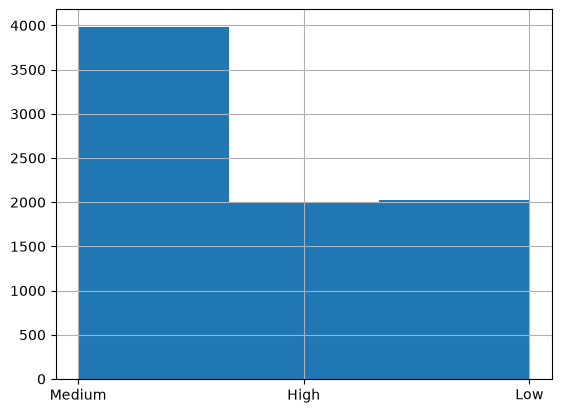

In [52]:
y_train.hist(bins=3)

In [53]:
# Impute Age with mean value to fill the nan values
import pandas as pd
from sklearn.impute import SimpleImputer

# 1. Initialize the imputer (e.g., using the median strategy)
imputer = SimpleImputer(strategy="mean")

# 2. Fit and transform the specific column (Notice the double brackets)
X["Age"] = imputer.fit_transform(X[["Age"]])

X['Age'].sum()

np.float64(317310.8695652174)